In [66]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')

# Dataset Loading
In this section, we locate the dataset files available in the Kaggle environment. This step helps us identify the file path before loading the SMS Spam Collection dataset into our project.

In [67]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.lower().endswith('.csv'):
            print(os.path.join(dirname, filename))

/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


# Loading the Dataset
In this step, we load the SMS Spam Collection dataset using Pandas. The dataset contains SMS messages labeled as either spam or ham. We will use these messages to build our binary classification model.

In [68]:
df = pd.read_csv("/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv", encoding="latin-1")

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


# Data Exploration
In this section, we will explore the dataset structure, column names, and missing values to understand the data before preprocessing.

In [69]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (5572, 5)

Column Names:
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB

Missing Values:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


# Data Cleaning and Preprocessing
In this section, we will remove unnecessary columns, keep the SMS labels and message text, and convert the labels into numerical values for Logistic Regression.

In [70]:
# Keep only the required columns
df = df[['v1', 'v2']].copy()

# Rename columns
df.columns = ['label', 'message']

# Convert labels into numerical values
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

# Display the cleaned dataset
print(df.head())

print("\nClass Distribution:")
print(df['label'].value_counts())

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...

Class Distribution:
label
0    4825
1     747
Name: count, dtype: int64


# Train-Test Split
In this section, we will split the dataset into training and testing sets. We will use 80% of the data for training and 20% for testing while maintaining the same class distribution.

In [71]:
X = df['message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4457
Testing samples: 1115


# Text Vectorization using TF-IDF
In this section, we will convert SMS messages into numerical features using TF-IDF. This allows the Logistic Regression model to process text data. We will fit the vectorizer on the training data and apply it to the testing data.

In [72]:
tfidf = TfidfVectorizer(max_features=3000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4457, 3000)
Testing data shape: (1115, 3000)


# Logistic Regression Model
In this section, we will implement Logistic Regression from scratch. We will define the Sigmoid function to calculate probabilities and the Binary Cross-Entropy Loss to measure prediction errors. These functions will be used by all five optimization algorithms.

In [73]:
# Sigmoid Function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# Binary Cross-Entropy Loss
def compute_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


# Calculate Gradients
def compute_gradients(X, y, weights, bias):
    n = X.shape[0]

    predictions = sigmoid(X @ weights + bias)
    errors = predictions - y

    dw = np.asarray(X.T @ errors).ravel() / n
    db = np.mean(errors)

    return dw, db

# Stochastic Gradient Descent with Momentum (SGD)

In this section, we will implement Stochastic Gradient Descent with Momentum to train the Logistic Regression model and minimize the Binary Cross-Entropy Loss.

In [74]:
def train_sgd_momentum(X, y, learning_rate=0.01, momentum=0.9, epochs=100):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    velocity_w = np.zeros(n_features)
    velocity_b = 0.0

    losses = []

    for epoch in range(epochs):

        indices = np.random.permutation(n_samples)

        for i in indices:

            X_i = X[i:i+1]
            y_i = y[i:i+1]

            dw, db = compute_gradients(X_i, y_i, weights, bias)

            velocity_w = momentum * velocity_w + learning_rate * dw
            velocity_b = momentum * velocity_b + learning_rate * db

            weights -= velocity_w
            bias -= velocity_b

        predictions = sigmoid(X @ weights + bias)
        loss = compute_loss(y, predictions)
        losses.append(loss)

    return weights, bias, losses

In [75]:
weights_sgd, bias_sgd, losses_sgd = train_sgd_momentum(
    X_train_tfidf,
    y_train.to_numpy(),
    learning_rate=0.01,
    momentum=0.9,
    epochs=100
)

print("Final Training Loss:", losses_sgd[-1])

Final Training Loss: 0.013963400950036174


### Model Evaluation

In this section, we will evaluate the performance of the SGD with Momentum model using Accuracy, Precision, Recall, F1 Score, and Test Loss.

In [76]:
y_test_array = y_test.to_numpy()

y_prob_sgd = sigmoid(X_test_tfidf @ weights_sgd + bias_sgd)
y_pred_sgd = (y_prob_sgd >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test_array, y_pred_sgd))
print("Precision:", precision_score(y_test_array, y_pred_sgd, zero_division=0))
print("Recall:", recall_score(y_test_array, y_pred_sgd, zero_division=0))
print("F1 Score:", f1_score(y_test_array, y_pred_sgd, zero_division=0))
print("Test Loss:", compute_loss(y_test_array, y_prob_sgd))

Accuracy: 0.9838565022421525
Precision: 0.9851851851851852
Recall: 0.8926174496644296
F1 Score: 0.9366197183098591
Test Loss: 0.05806269948862013


### Confusion Matrix

The Confusion Matrix shows how well the SGD with Momentum model classifies Ham and Spam messages by displaying correct and incorrect predictions.

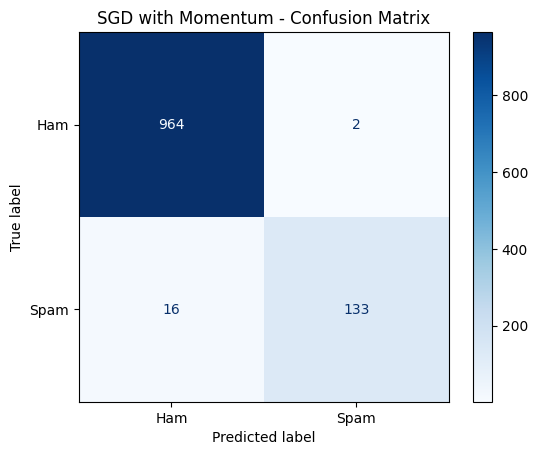

In [77]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_array, y_pred_sgd)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Ham', 'Spam']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('SGD with Momentum - Confusion Matrix')
plt.show()

# Evaluation Metrics Visualization

This bar chart compares the evaluation metrics of the SGD with Momentum model.

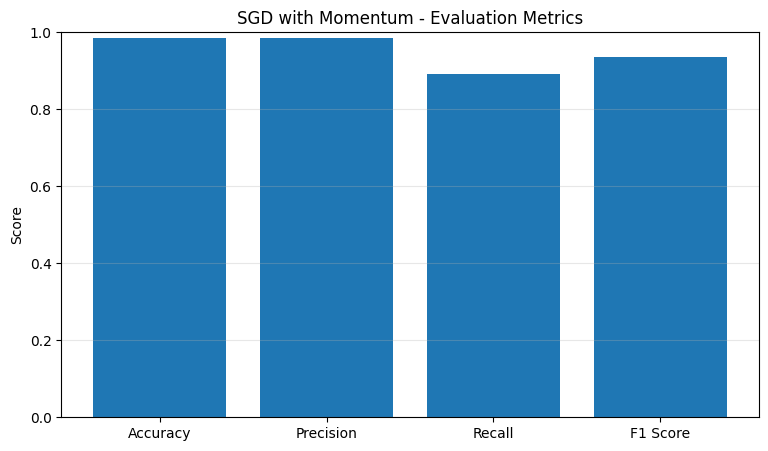

In [78]:
metrics = {
    'Accuracy': accuracy_score(y_test_array, y_pred_sgd),
    'Precision': precision_score(y_test_array, y_pred_sgd, zero_division=0),
    'Recall': recall_score(y_test_array, y_pred_sgd, zero_division=0),
    'F1 Score': f1_score(y_test_array, y_pred_sgd, zero_division=0)
}

plt.figure(figsize=(9, 5))
plt.bar(metrics.keys(), metrics.values())
plt.title('SGD with Momentum - Evaluation Metrics')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)
plt.show()

# Training Loss Curve

The training loss curve shows how the Binary Cross-Entropy Loss changes during training over the epochs.

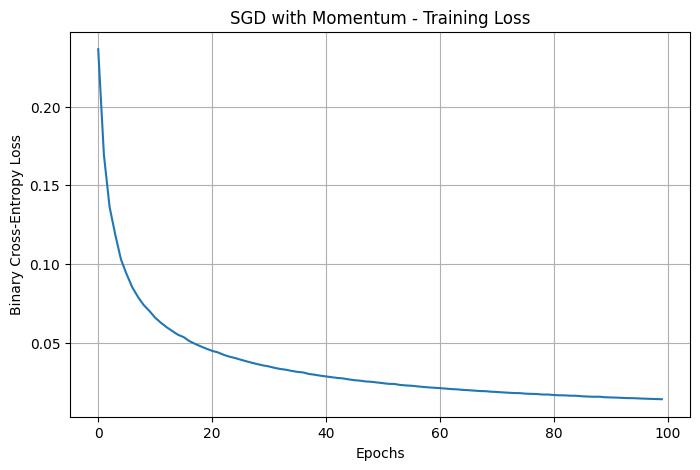

In [79]:
plt.figure(figsize=(8, 5))
plt.plot(losses_sgd)
plt.title("SGD with Momentum - Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True)
plt.show()

The training loss curve shows a steady decrease in Binary Cross-Entropy Loss over 100 epochs. The loss decreases rapidly at the beginning and then gradually stabilizes, indicating that the SGD with Momentum optimizer successfully learns the model parameters.

In [80]:
results = {
    'Parameter': [
        'Optimizer',
        'Learning Rate',
        'Momentum',
        'Epochs',
        'Training Loss',
        'Test Loss',
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ],
    'Value': [
        'SGD with Momentum',
        0.01,
        0.9,
        100,
        losses_sgd[-1],
        compute_loss(y_test_array, y_prob_sgd),
        accuracy_score(y_test_array, y_pred_sgd),
        precision_score(y_test_array, y_pred_sgd),
        recall_score(y_test_array, y_pred_sgd),
        f1_score(y_test_array, y_pred_sgd)
    ]
}

pd.DataFrame(results)

,Parameter,Value
0,Optimizer,SGD with Momentum
1,Learning Rate,0.01
2,Momentum,0.9
3,Epochs,100
4,Training Loss,0.013963
5,Test Loss,0.058063
6,Accuracy,0.983857
7,Precision,0.985185
8,Recall,0.892617
9,F1 Score,0.93662
